In [ ]:
#acces a servidor
import os
import requests
#avg_no2 --> avg
#detailed_no2 --> hores
option_db = 'avg_no2'
pollutant = requests.get('http://mappo-server.herokuapp.com/database?option='+option_db)


pollutant = str(pollutant.content)
primer_caracter = False
last_char = ''
#print(pollutant)
with open(option_db+'.csv', 'w') as f:

    if "detailed" not in option_db:
        f.write("estacio,data,contaminant,unitats,latitud,longitud,valor,\n")
    else:
        f.write("estacio,data,contaminant,unitats,latitud,longitud,quantity,\n")

    for c in pollutant:
        if c == '(':
            primer_caracter = True
            
        if (c >= '0' and c <= '9' or c >= 'A' and c <= 'Z' or c >= 'a' and c <= 'z' or c == '.' or c == '-' or c == ',' or c == ' ' or c == ':') and primer_caracter==True:
            last_char = c
            f.write(c)

        elif c == ')' and primer_caracter == True:
            f.write(',')
            last_char = c
            f.write('\n')
            primer_caracter = False


In [ ]:
#Para avg no2 seleccionar este
import numpy as np
import pandas as pd
import psycopg2
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import date
from sklearn.preprocessing import LabelEncoder

dataset = pd.read_csv('/content/avg_no2.csv', sep = ',', index_col = 1)#index_col=1
df_avg = pd.DataFrame(dataset, columns=['estacio', 'contaminant', 'unitats', 'latitud', 'longitud', 'valor'])

df_avg.head()

,estacio,contaminant,unitats,latitud,longitud,valor
data,,,,,,
2022-01-01,Ciutadella,NO2,xc2xb5gm3,41.386406,2.187398,32.625000
2022-01-02,Ciutadella,NO2,xc2xb5gm3,41.386406,2.187398,23.750000
2022-01-03,Ciutadella,NO2,xc2xb5gm3,41.386406,2.187398,37.545455
2022-01-04,Ciutadella,NO2,xc2xb5gm3,41.386406,2.187398,52.500000
2022-01-05,Ciutadella,NO2,xc2xb5gm3,41.386406,2.187398,26.833333


In [ ]:
#Para horas seleccionar este
#Detailed 7 dies
import numpy as np
import pandas as pd
import psycopg2
import seaborn as sns
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import date

dataset = pd.read_csv('/content/detailed_no2.csv', sep = ',', index_col=1)
df = pd.DataFrame(dataset, columns=['estacio', 'contaminant', 'unitats', 'latitud', 'longitud', 'quantity'])
df.tail()


/usr/local/lib/python3.7/dist-packages/psycopg2/__init__.py:144: UserWarning: The psycopg2 wheel package will be renamed from release 2.8; in order to keep installing from binary please use "pip install psycopg2-binary" instead. For details see: <http://initd.org/psycopg/docs/install.html#binary-install-from-pypi>.
  """)


,estacio,contaminant,unitats,latitud,longitud,quantity
data,,,,,,
2022-04-22 20:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,32.0
2022-04-22 21:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,30.0
2022-04-22 22:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,37.0
2022-04-22 23:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,43.0
2022-04-23 00:00:00,Grxc3xa0cia - Sant Gervasi,NO2,xc2xb5gm3,41.398724,2.153399,34.0


In [ ]:
import os
#Acces a base de dades 


conn = psycopg2.connect(os.environ["DATABASE_URL"])
dataset = pd.read_sql_query("""
                        SELECT nom_estacio, "data", contaminant, unitats, latitud, longitud, quantity
                        FROM public."detailedNO2"
                        """, conn)

df = pd.DataFrame(dataset, columns=['nom_estacio', 'data', 'contaminant', 'unitats', 'latitud', 'longitud', 'quantity'])
df.head()
#'h01', 'h02', 'h03', 'h04', 'h05', 'h06', 'h07', 'h08', 'h09', 'h10', 'h11', 'h12', 'h13', 'h14', 'h15', 'h16', 'h17', 'h18', 'h19', 'h20', 'h21', 'h22', 'h23', 'h24'

,nom_estacio,data,contaminant,unitats,latitud,longitud,quantity
0,Ciutadella,2022-04-25 22:00:00,NO2,µg/m3,41.386406,2.1873982,41.0
1,Ciutadella,2022-04-25 23:00:00,NO2,µg/m3,41.386406,2.1873982,32.0
2,Ciutadella,2022-04-25 24:00:00,NO2,µg/m3,41.386406,2.1873982,37.0
3,Palau Reial,2022-04-25 01:00:00,NO2,µg/m3,41.38749,2.1151996,37.0
4,Palau Reial,2022-04-25 02:00:00,NO2,µg/m3,41.38749,2.1151996,24.0


In [ ]:
avg = df_avg['valor']
df.assign(avg = avg)
#da error

ValueError: ignored

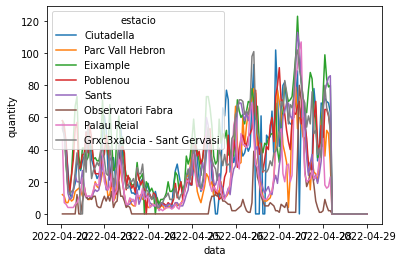

In [ ]:
#Fer gràfica de dades per hores 
#Quan tinguem les noves dades de 7 dies per hores.
#avg = df_avg['valor']
#df.assign(avg = avg)
df['data'] = pd.to_datetime(df['data'])
df = df.sort_values(by='data')
df.head()

sns.lineplot(x = 'data', y = "quantity", hue="estacio", data = df)

#sns.lineplot(x = "data", y = 'quantity')



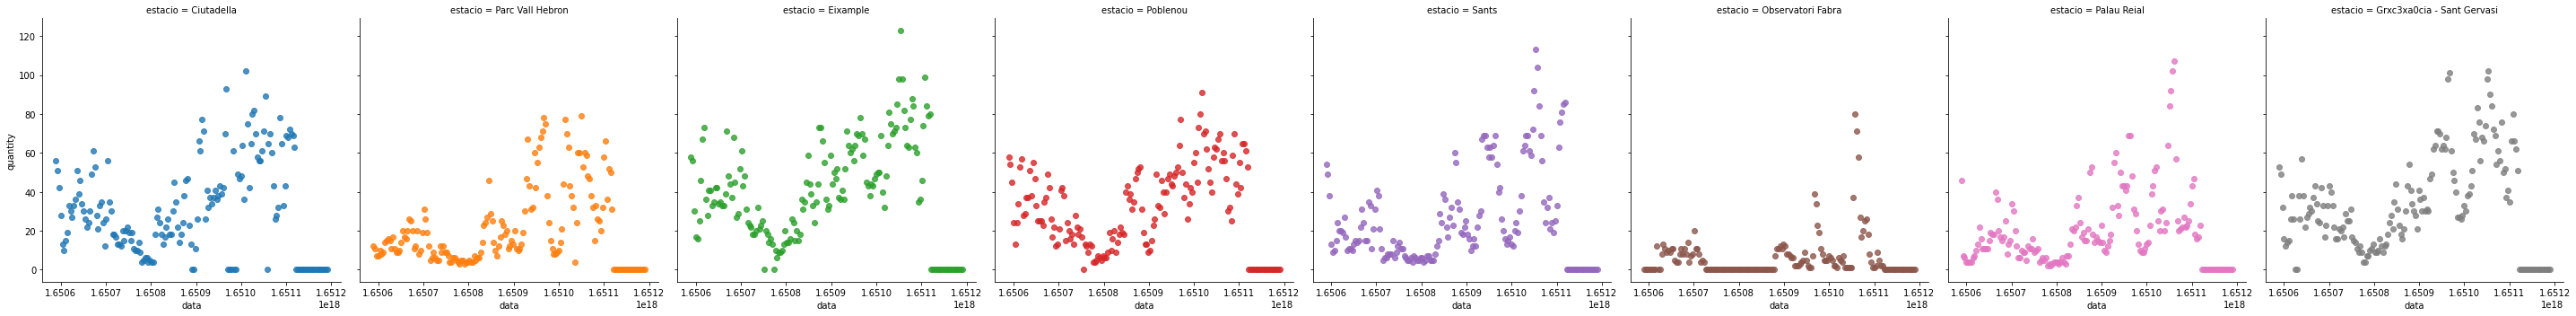

In [ ]:
df['data'] = pd.to_numeric(pd.to_datetime(df['data']))

df = df.sort_values(by='data')

sns.lmplot(x="data", y='quantity', data=df, hue='estacio', col= 'estacio', fit_reg=False);

In [ ]:
#Grafica per hores i per estacio
#Conclusió: escala cada 1 hora.
df = df.sort_values(by='data')
sns.relplot(
    data=df, x="data", y="quantity", 
    row="estacio",
    height=3, aspect=3.5,
    kind="line"
)


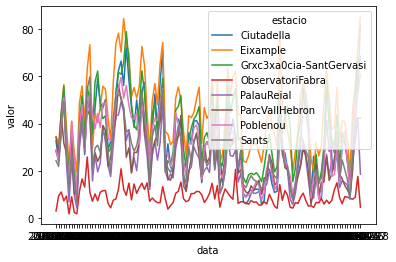

In [ ]:
#grafica dades average 
avg = df_avg['valor']
#df.assign(avg = avg)

df['data'] = pd.to_datetime(df['data'])
df = df.sort_values(by='data')
df.head()

sns.lineplot(x = 'data', y = "valor", hue="estacio", data = df_avg)

In [ ]:
# convert an array of values into a dataset matrix
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	df = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

In [ ]:
np.random.seed(7)
df.drop('contaminant', 1, inplace=True)
df.drop('unitats', 1, inplace=True)
df.drop('estacio', 1, inplace=True)

values = df.values

# integer encode direction
encoder = LabelEncoder()
values[:,2] = encoder.fit_transform(values[:,2])

print(values)
# ensure all data is float
values = values.astype('float32')

#normalize dataset
scaler = MinMaxScaler(feature_range=(0,1))
#scaled = scaler.fit_transform(df['quantity'].array.reshape(-1,1)) #reshape(-1,1) porque sólo es una feature
scaled = scaler.fit_transform(values)

# frame as supervised learning
n_hours = 1
n_features = 3
reframed = series_to_supervised(scaled, n_hours, 3) #reframed = series_to_supervised(scaled, n_hours, 1)

# drop columns we don't want to predict
#reframed.drop(reframed.columns[[9,10,11,12,13,14,15]], axis=1, inplace=True)
reframed.drop(reframed.columns[[3,4]], axis=1, inplace=True)
reframed.tail()

[[41.42611    2.1480017 36.       ]
 [41.42611    2.1480017 52.       ]
 [41.42611    2.1480017 50.       ]
 ...
 [41.398724   2.1533988 37.       ]
 [41.398724   2.1533988 43.       ]
 [41.398724   2.1533988 34.       ]]


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:3: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  This is separate from the ipykernel package so we can avoid doing imports until
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  after removing the cwd from sys.path.


,var1(t-3),var2(t-3),var3(t-3),var3(t-2),var1(t-1),var2(t-1),var3(t-1),var1(t),var2(t),var3(t)
1339,0.421326,0.427757,0.22,0.27,0.421326,0.427757,0.29,0.421326,0.427757,0.32
1340,0.421326,0.427757,0.27,0.29,0.421326,0.427757,0.32,0.421326,0.427757,0.30
1341,0.421326,0.427757,0.29,0.32,0.421326,0.427757,0.30,0.421326,0.427757,0.37
1342,0.421326,0.427757,0.32,0.30,0.421326,0.427757,0.37,0.421326,0.427757,0.43
1343,0.421326,0.427757,0.30,0.37,0.421326,0.427757,0.43,0.421326,0.427757,0.34


In [ ]:
#Total dataset: de 01-01 a 03-21
#Train: 01-01 a 02-28 ; Val: 03-01 a 03-28; Test: 03-29 a 04-29 mes o menys
#De momento no se usa esto
trainX = df[(df['data'] > '2022-01-01') & (df['data'] < '2022-02-28')]
valX = df[(df['data'] > '2022-03-01') & (df['data'] < '2022-03-21')]
print(len(trainX))
print(len(valX))


# reshape into X=t and Y=t+1
look_back = 1
trainX, trainY = create_dataset(trainX.values, look_back) #con trainX.values no peta pero trainX = nom_estacio
valX, valY = create_dataset(valX.values, look_back)

#reshape input to be [samples, time steps, features]
print(trainX.shape)
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
valX = np.reshape(valX, (valX.shape[0], 1, valX.shape[1]))

KeyError: ignored

In [ ]:
# split into train and test sets
values = reframed.values
n_train_hours = 52 * 24 #REVISAR VALOR
train = values[:n_train_hours, :]
test = values[n_train_hours:, :]
# split into input and outputs

n_obs = n_hours * n_features
train_X, train_y = train[:, :n_obs], train[:, -n_features]
test_X, test_y = test[:, :n_obs], test[:, -n_features]
print(train_X.shape, len(train_X), train_y.shape)
#Abans sense multiple time lagstamps
#train_X, train_y = train[:, :-1], train[:, -1]
#test_X, test_y = test[:, :-1], test[:, -1]

# reshape input to be 3D [samples, timesteps, features]
#train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1]))
#test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
#print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

# reshape input to be 3D [samples, timesteps, features]
train_X = train_X.reshape((train_X.shape[0], n_hours, n_features))
test_X = test_X.reshape((test_X.shape[0], n_hours, n_features))

(1248, 9) 1248 (1248,)


Epoch 1/50
18/18 - 3s - loss: 0.3414 - val_loss: 0.1436 - 3s/epoch - 155ms/step
Epoch 2/50
18/18 - 0s - loss: 0.2228 - val_loss: 0.1251 - 79ms/epoch - 4ms/step
Epoch 3/50
18/18 - 0s - loss: 0.1967 - val_loss: 0.0994 - 73ms/epoch - 4ms/step
Epoch 4/50
18/18 - 0s - loss: 0.1639 - val_loss: 0.0874 - 71ms/epoch - 4ms/step
Epoch 5/50
18/18 - 0s - loss: 0.1332 - val_loss: 0.0672 - 73ms/epoch - 4ms/step
Epoch 6/50
18/18 - 0s - loss: 0.0944 - val_loss: 0.0524 - 75ms/epoch - 4ms/step
Epoch 7/50
18/18 - 0s - loss: 0.0546 - val_loss: 0.0477 - 71ms/epoch - 4ms/step
Epoch 8/50
18/18 - 0s - loss: 0.0480 - val_loss: 0.0421 - 70ms/epoch - 4ms/step
Epoch 9/50
18/18 - 0s - loss: 0.0449 - val_loss: 0.0402 - 89ms/epoch - 5ms/step
Epoch 10/50
18/18 - 0s - loss: 0.0434 - val_loss: 0.0388 - 76ms/epoch - 4ms/step
Epoch 11/50
18/18 - 0s - loss: 0.0414 - val_loss: 0.0369 - 87ms/epoch - 5ms/step
Epoch 12/50
18/18 - 0s - loss: 0.0398 - val_loss: 0.0350 - 72ms/epoch - 4ms/step
Epoch 13/50
18/18 - 0s - loss: 0.0384

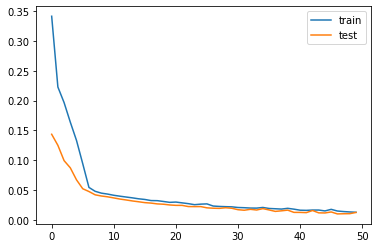

In [ ]:
# design network
model = Sequential()
model.add(LSTM(50, input_shape=(train_X.shape[1], train_X.shape[2])))
model.add(Dense(1))
model.compile(loss='mae', optimizer='adam')
# fit network
history = model.fit(train_X, train_y, epochs=50, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)
print(history)
# plot history
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [ ]:
from math import sqrt
from numpy import concatenate
# make a prediction
yhat = model.predict(test_X)
test_X = test_X.reshape((test_X.shape[0], test_X.shape[2]))
# invert scaling for forecast
inv_yhat = concatenate((yhat, test_X[:, 1:]), axis=1)
inv_yhat = scaler.inverse_transform(inv_yhat)
inv_yhat = inv_yhat[:,0]
# invert scaling for actual
test_y = test_y.reshape((len(test_y), 1))
inv_y = concatenate((test_y, test_X[:, 1:]), axis=1)
inv_y = scaler.inverse_transform(inv_y)
inv_y = inv_y[:,0]
# calculate RMSE
rmse = sqrt(mean_squared_error(inv_y, inv_yhat))
print('Test RMSE: %.3f' % rmse)

ValueError: ignored

In [ ]:
from math import sqrt
from numpy import concatenate
#WITH Multiple Lag Timesteps
# make a prediction
yhat = model.predict(test_X)
test_X = test_X.reshape((test_X.shape[0], n_hours*n_features))
# invert scaling for forecast
inv_yhat = concatenate((yhat, test_X[:, -2:]), axis=1)
inv_yhat = scaler.inverse_transform(inv_yhat)
inv_yhat = inv_yhat[:,0]
# invert scaling for actual
test_y = test_y.reshape((len(test_y), 1))
inv_y = concatenate((test_y, test_X[:, -2:]), axis=1)
inv_y = scaler.inverse_transform(inv_y)
inv_y = inv_y[:,0]
# calculate RMSE
rmse = sqrt(mean_squared_error(inv_y, inv_yhat))
print('Test RMSE: %.3f' % rmse)

Test RMSE: 0.002
